In [41]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

print("All Libraries Imported Successfully!")

All Libraries Imported Successfully!


In [42]:
df = pd.read_csv("customer_spending_dataset.csv")

df.head()

,Customer_ID,Gender,Age,Annual_Income_k,Purchase_Frequency,Average_Purchase_Amount,Online_Shopping_Frequency,Spending_Category
0,1001,Male,22,53.3,6,47.34,2,Medium
1,1002,Male,55,75.3,8,65.50,3,Medium
2,1003,Female,49,15.0,6,54.25,4,Low
3,1004,Female,39,28.1,5,30.27,2,Low
4,1005,Female,38,38.4,8,61.74,7,Medium


In [43]:
df.shape

(500, 8)

In [44]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 500 entries, 0 to 499
Data columns (total 8 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Customer_ID                500 non-null    int64  
 1   Gender                     500 non-null    str    
 2   Age                        500 non-null    int64  
 3   Annual_Income_k            500 non-null    float64
 4   Purchase_Frequency         500 non-null    int64  
 5   Average_Purchase_Amount    500 non-null    float64
 6   Online_Shopping_Frequency  500 non-null    int64  
 7   Spending_Category          500 non-null    str    
dtypes: float64(2), int64(4), str(2)
memory usage: 31.4 KB


In [45]:
df.describe()

,Customer_ID,Age,Annual_Income_k,Purchase_Frequency,Average_Purchase_Amount,Online_Shopping_Frequency
count,500.000000,500.00000,500.000000,500.000000,500.00000,500.000000
mean,1250.500000,41.45000,54.919400,6.002000,68.07704,3.322000
std,144.481833,13.70749,17.770449,2.290084,18.92615,1.730985
min,1001.000000,18.00000,15.000000,1.000000,12.53000,0.000000
25%,1125.750000,30.00000,43.125000,4.000000,55.31000,2.000000
50%,1250.500000,41.00000,55.300000,6.000000,67.39500,3.000000
75%,1375.250000,53.25000,66.400000,7.000000,80.94000,4.000000
max,1500.000000,65.00000,112.200000,14.000000,132.14000,11.000000


In [46]:
df.isnull().sum()

Customer_ID                  0
Gender                       0
Age                          0
Annual_Income_k              0
Purchase_Frequency           0
Average_Purchase_Amount      0
Online_Shopping_Frequency    0
Spending_Category            0
dtype: int64

In [47]:
df.duplicated().sum()

np.int64(0)

In [48]:
df = df.drop_duplicates()

df = df.dropna()

print("Data Cleaning Completed!")
print(df.shape)

Data Cleaning Completed!
(500, 8)


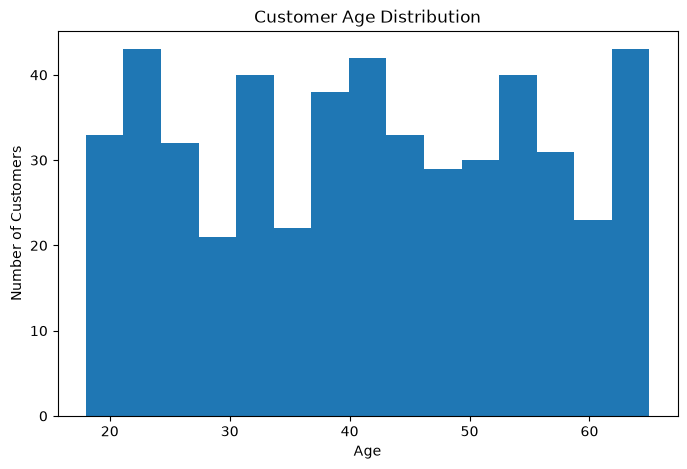

In [49]:
plt.figure(figsize=(8,5))

plt.hist(df["Age"], bins=15)

plt.title("Customer Age Distribution")
plt.xlabel("Age")
plt.ylabel("Number of Customers")

plt.show()

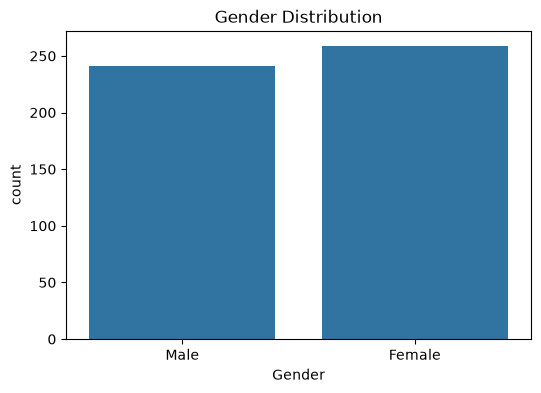

In [50]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="Gender")

plt.title("Gender Distribution")

plt.show()

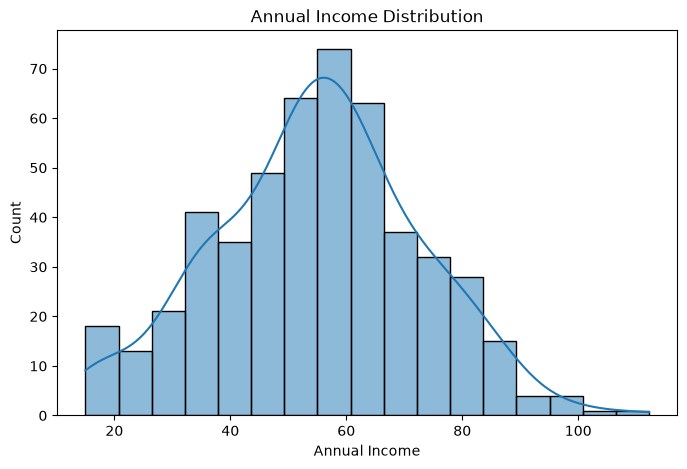

In [51]:
plt.figure(figsize=(8,5))

sns.histplot(df["Annual_Income_k"], kde=True)

plt.title("Annual Income Distribution")
plt.xlabel("Annual Income")

plt.show()

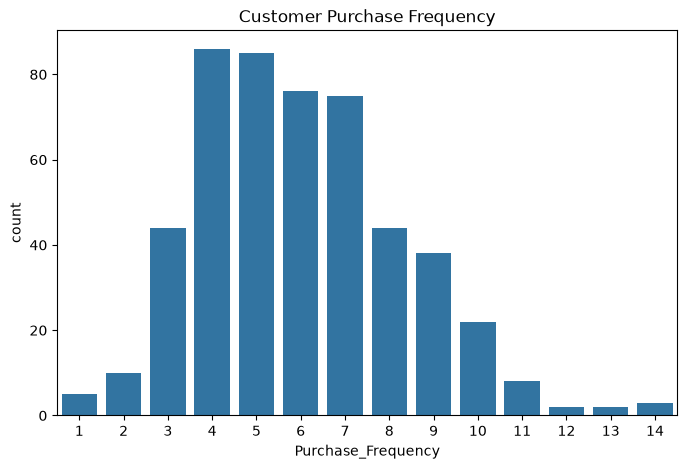

In [52]:
plt.figure(figsize=(8,5))

sns.countplot(data=df, x="Purchase_Frequency")

plt.title("Customer Purchase Frequency")

plt.show()

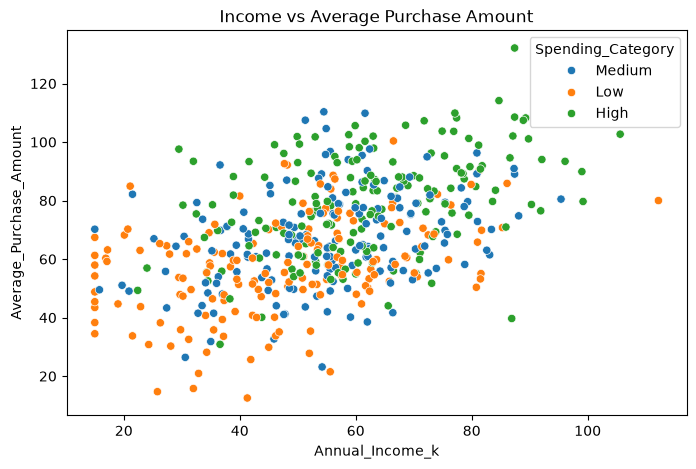

In [53]:
plt.figure(figsize=(8,5))

sns.scatterplot(
    data=df,
    x="Annual_Income_k",
    y="Average_Purchase_Amount",
    hue="Spending_Category"
)

plt.title("Income vs Average Purchase Amount")

plt.show()

In [54]:
df["Spending_Category"].value_counts()

Spending_Category
Low       167
High      167
Medium    166
Name: count, dtype: int64

In [55]:
X = df.drop(
    ["Customer_ID", "Spending_Category"],
    axis=1
)

y = df["Spending_Category"]

print("Input Features:")
print(X.head())

print("Target:")
print(y.head())

Input Features:
   Gender  Age  Annual_Income_k  Purchase_Frequency  Average_Purchase_Amount  \
0    Male   22             53.3                   6                    47.34   
1    Male   55             75.3                   8                    65.50   
2  Female   49             15.0                   6                    54.25   
3  Female   39             28.1                   5                    30.27   
4  Female   38             38.4                   8                    61.74   

   Online_Shopping_Frequency  
0                          2  
1                          3  
2                          4  
3                          2  
4                          7  
Target:
0    Medium
1    Medium
2       Low
3       Low
4    Medium
Name: Spending_Category, dtype: str


In [56]:
X = pd.get_dummies(
    X,
    columns=["Gender"],
    drop_first=True,
    dtype=int
)

X.head()

,Age,Annual_Income_k,Purchase_Frequency,Average_Purchase_Amount,Online_Shopping_Frequency,Gender_Male
0,22,53.3,6,47.34,2,1
1,55,75.3,8,65.50,3,1
2,49,15.0,6,54.25,4,0
3,39,28.1,5,30.27,2,0
4,38,38.4,8,61.74,7,0


In [57]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training Data:", X_train.shape)
print("Testing Data:", X_test.shape)

Training Data: (400, 6)
Testing Data: (100, 6)


In [58]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

dt_model.fit(X_train, y_train)

dt_prediction = dt_model.predict(X_test)

print("Decision Tree Model Completed!")

Decision Tree Model Completed!


In [59]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

rf_model.fit(X_train, y_train)

rf_prediction = rf_model.predict(X_test)

print("Random Forest Model Completed!")

Random Forest Model Completed!


In [60]:
from sklearn.metrics import accuracy_score

dt_accuracy = accuracy_score(y_test, dt_prediction)

rf_accuracy = accuracy_score(y_test, rf_prediction)

print("Decision Tree Accuracy:", dt_accuracy)

print("Random Forest Accuracy:", rf_accuracy)

Decision Tree Accuracy: 0.58
Random Forest Accuracy: 0.58


In [61]:
from sklearn.metrics import classification_report

print("DECISION TREE REPORT")

print(classification_report(y_test, dt_prediction))

print("RANDOM FOREST REPORT")

print(classification_report(y_test, rf_prediction))

DECISION TREE REPORT
              precision    recall  f1-score   support

        High       0.71      0.50      0.59        34
         Low       0.69      0.61      0.65        33
      Medium       0.45      0.64      0.53        33

    accuracy                           0.58       100
   macro avg       0.61      0.58      0.59       100
weighted avg       0.62      0.58      0.59       100

RANDOM FOREST REPORT
              precision    recall  f1-score   support

        High       0.62      0.71      0.66        34
         Low       0.63      0.67      0.65        33
      Medium       0.46      0.36      0.41        33

    accuracy                           0.58       100
   macro avg       0.57      0.58      0.57       100
weighted avg       0.57      0.58      0.57       100



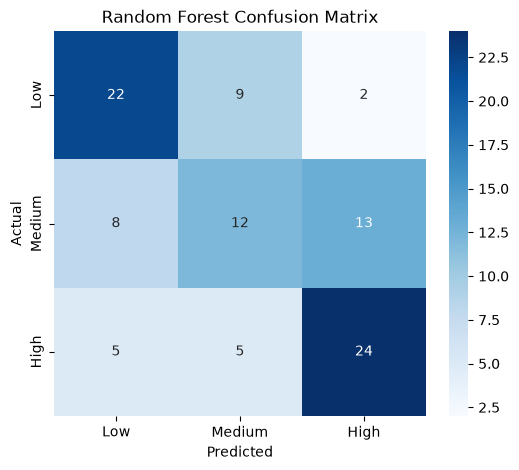

In [62]:
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    rf_prediction,
    labels=["Low", "Medium", "High"]
)

plt.figure(figsize=(6,5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Low", "Medium", "High"],
    yticklabels=["Low", "Medium", "High"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")

plt.title("Random Forest Confusion Matrix")

plt.show()

In [63]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": rf_model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

print(importance)

                     Feature  Importance
3    Average_Purchase_Amount    0.281299
1            Annual_Income_k    0.233091
0                        Age    0.188572
2         Purchase_Frequency    0.155304
4  Online_Shopping_Frequency    0.103249
5                Gender_Male    0.038484


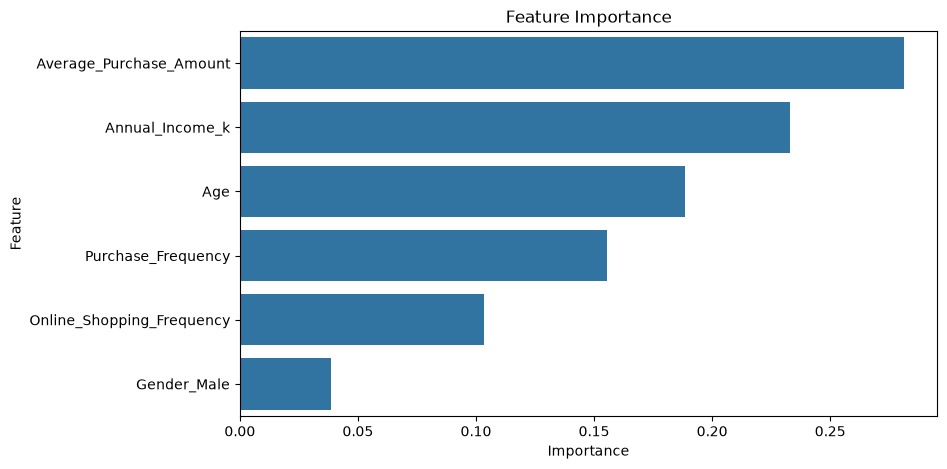

In [64]:
plt.figure(figsize=(9,5))

sns.barplot(
    data=importance,
    x="Importance",
    y="Feature"
)

plt.title("Feature Importance")

plt.show()

In [65]:
new_customer = pd.DataFrame({
    "Age": [25],
    "Annual_Income_k": [60],
    "Purchase_Frequency": [8],
    "Average_Purchase_Amount": [85],
    "Online_Shopping_Frequency": [6],
    "Gender_Male": [0]
})

prediction = rf_model.predict(new_customer)

print("Predicted Spending Category:", prediction[0])

Predicted Spending Category: High


In [66]:
print("CUSTOMER SPENDING ANALYSIS REPORT")

print("--------------------------------")

print("Total Customers:", len(df))

print("\nSpending Category Distribution:")

print(df["Spending_Category"].value_counts())

print("\nAverage Annual Income:")

print(df["Annual_Income_k"].mean())

print("\nAverage Purchase Amount:")

print(df["Average_Purchase_Amount"].mean())

print("\nBest Model: Random Forest")

print("Random Forest Accuracy:", rf_accuracy)

print("\nAnalysis Completed Successfully!")

CUSTOMER SPENDING ANALYSIS REPORT
--------------------------------
Total Customers: 500

Spending Category Distribution:
Spending_Category
Low       167
High      167
Medium    166
Name: count, dtype: int64

Average Annual Income:
54.9194

Average Purchase Amount:
68.07704000000001

Best Model: Random Forest
Random Forest Accuracy: 0.58

Analysis Completed Successfully!


In [67]:
model_comparison = pd.DataFrame({
    "Model": ["Decision Tree", "Random Forest"],
    "Accuracy": [dt_accuracy, rf_accuracy]
})

print(model_comparison)

           Model  Accuracy
0  Decision Tree      0.58
1  Random Forest      0.58


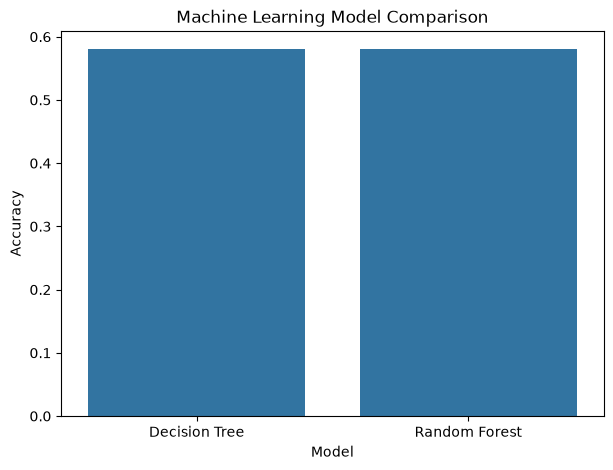

In [68]:
plt.figure(figsize=(7,5))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="Accuracy"
)

plt.title("Machine Learning Model Comparison")
plt.ylabel("Accuracy")

plt.show()

In [69]:
df.to_csv("cleaned_customer_dataset.csv", index=False)

print("Cleaned Dataset Saved Successfully!")

Cleaned Dataset Saved Successfully!


In [70]:
model_comparison.to_csv(
    "model_comparison_results.csv",
    index=False
)

print("Model Comparison Results Saved!")

Model Comparison Results Saved!


In [71]:
report = f"""
AI-BASED CUSTOMER SPENDING PREDICTION
-------------------------------------

Total Customers: {len(df)}

Low Spending Customers:
{(df['Spending_Category'] == 'Low').sum()}

Medium Spending Customers:
{(df['Spending_Category'] == 'Medium').sum()}

High Spending Customers:
{(df['Spending_Category'] == 'High').sum()}

Decision Tree Accuracy: {dt_accuracy:.2%}

Random Forest Accuracy: {rf_accuracy:.2%}

Best Model: {
    'Random Forest' if rf_accuracy >= dt_accuracy
    else 'Decision Tree'
}

Conclusion:
Machine Learning helps businesses understand
customer spending behaviour and identify
different customer spending categories.
"""

print(report)

with open("business_insight_report.txt", "w") as file:
    file.write(report)

print("Business Report Saved Successfully!")


AI-BASED CUSTOMER SPENDING PREDICTION
-------------------------------------

Total Customers: 500

Low Spending Customers:
167

Medium Spending Customers:
166

High Spending Customers:
167

Decision Tree Accuracy: 58.00%

Random Forest Accuracy: 58.00%

Best Model: Random Forest

Conclusion:
Machine Learning helps businesses understand
customer spending behaviour and identify
different customer spending categories.

Business Report Saved Successfully!
